# Case study with linear models (10pts)
# Motivation
Modeling the sale price of a home could be valuable for multiple reasons: 
- To a real estate investor, understanding the future value of a property can guide purchasing strategies. 
- To a home buyer, a model could help inform them which house, in a set of potential purchases, is reasonably priced. 
- From the perspective of a governing entity, understanding the determinants of sales price can inform policy that seeks to create affordable housing or highlight and respond to volatility in housing markets.

# Overview
In this assignment, we will apply linear regression, polynomial regression, and
regularization techniques to predict the sale price of houses. The [dataset](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data) we use contains a rich set of features: 79 explanatory variables describing various  aspects of residential homes in Ames, Iowa.


# Goals

1) Predict the sales price of a home using a real-world dataset

2) Use regularization to avoid overfitting and improve model performance 

3) Explain how machine learning help us better understand variation in housing prices


In [88]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# Exploratory Data Analysis (EDA)

In [89]:
# Import data and check basic information
# Note: please use the dataset we provided on Canvas, do not use the one posted on Kaggle
df = pd.read_csv('./house_data.csv')
df.shape

(2919, 81)

In [90]:
# View variables
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [91]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500.0
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500.0
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500.0
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000.0
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000.0


## Explore target variable

The variable: SalePrice - the property's sale price in dollars

The aim here is to better understand our target and verify its integrity. We will look at some summary statistics, empirical distribution and missing values.

In [92]:
print(df.SalePrice.describe()) # Look at summary statistics
print()
print("Number of missing values: {}".format(df.SalePrice.isna().sum())) 
print("Proportion of missing values: {:.4f}".format(df.SalePrice.isna().sum()/len(df)))

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Number of missing values: 1459
Proportion of missing values: 0.4998


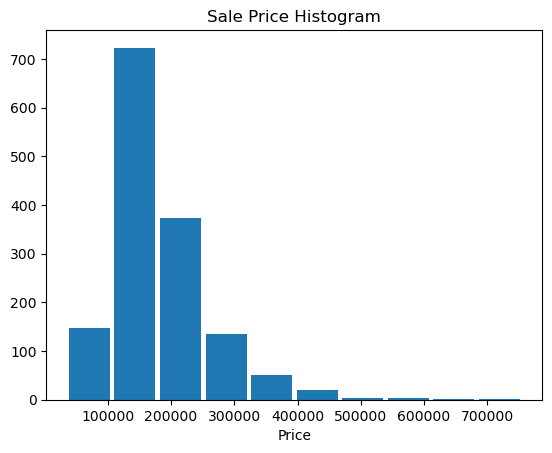

In [93]:
# Visualize the distribution
plt.hist(df.SalePrice, rwidth=0.9)
plt.xlabel('Price')
plt.title('Sale Price Histogram');

We gain some helpful informatino from all of this:
- First, we see that there are a significant amount of missing values -- we need to deal with these.
- Furthermore, we see that there are outliers on the upper end of the distribution, i.e., some houses are sold for extremely high prices.

Shape of data before dropping: (2919, 81)
Shape of data after dropping: (1460, 81)



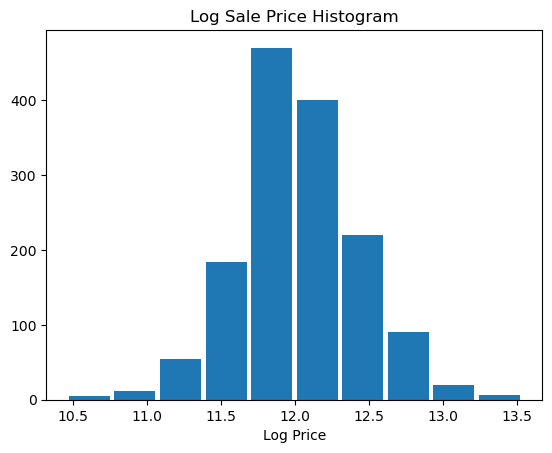

In [94]:
# Drop missing values
print('Shape of data before dropping: {}'.format(df.shape))
df_clean = df.drop(df[df['SalePrice'].isna()].index, axis=0)
# df['SalePrice'].isna() creates a boolean mask indicating where the 'SalePrice' column is NaN.
# df[df['SalePrice'].isna()] filters the DataFrame df to include only the rows where 'SalePrice' is NaN.
# df.drop(...) drops the rows corresponding to the boolean mask generated earlier.
# axis=0 specifies that rows should be dropped. axis=1 drops the columns

print('Shape of data after dropping: {}'.format(df_clean.shape))
print()

# Data transformation: take log of the target variable, to reduce the range of the prices
df_clean['lg_SalePrice'] = np.log(df['SalePrice'])

# Visualize the transformed distribution
plt.hist(df_clean.lg_SalePrice, rwidth=0.9)
plt.xlabel('Log Price')
plt.title('Log Sale Price Histogram');

## Explore feature variables

We will now apply a similar approach to explore our features:

1) Check for and deal with missing values

2) Determine feature types

3) Clean features based on their type



## Missing values

In [95]:
# Check missing values
null_perct = df_clean.isna().sum()/len(df_clean)
null_perct[null_perct>0]

LotFrontage     0.177397
Alley           0.937671
MasVnrType      0.597260
MasVnrArea      0.005479
BsmtQual        0.025342
BsmtCond        0.025342
BsmtExposure    0.026027
BsmtFinType1    0.025342
BsmtFinType2    0.026027
Electrical      0.000685
FireplaceQu     0.472603
GarageType      0.055479
GarageYrBlt     0.055479
GarageFinish    0.055479
GarageQual      0.055479
GarageCond      0.055479
PoolQC          0.995205
Fence           0.807534
MiscFeature     0.963014
dtype: float64

In [96]:
# Note that some features have a large portion of missing observations (e.g., PoolQC).
# In response, we will drop columns that have more than 30% missing values.
# Recall that there are other potential ways to deal with missing values, such as imputation, but this is not the focus of this assignment.

print(df_clean.shape)
df_clean = df_clean.drop(columns=df_clean.columns[null_perct > 0.3])
print(df_clean.shape)

# feature size reduced from 82 to 77

(1460, 82)
(1460, 76)


In [97]:
# Next, we will drop samples with any remaining missing values.
print(df_clean.shape)
df_final = df_clean.dropna().reset_index(drop=True)
print(df_final.shape)

# sample size reduced from 1460 to 1094

(1460, 76)
(1094, 76)


## Explore feature types

What kind of feature types do we have? Organize features into types.

### Begin with numeric variables

In [98]:
# Identify numeric types
df_final.select_dtypes(['int', 'float']).dtypes

Id                 int64
MSSubClass         int64
LotFrontage      float64
LotArea            int64
OverallQual        int64
OverallCond        int64
YearBuilt          int64
YearRemodAdd       int64
MasVnrArea       float64
BsmtFinSF1       float64
BsmtFinSF2       float64
BsmtUnfSF        float64
TotalBsmtSF      float64
1stFlrSF           int64
2ndFlrSF           int64
LowQualFinSF       int64
GrLivArea          int64
BsmtFullBath     float64
BsmtHalfBath     float64
FullBath           int64
HalfBath           int64
BedroomAbvGr       int64
KitchenAbvGr       int64
TotRmsAbvGrd       int64
Fireplaces         int64
GarageYrBlt      float64
GarageCars       float64
GarageArea       float64
WoodDeckSF         int64
OpenPorchSF        int64
EnclosedPorch      int64
3SsnPorch          int64
ScreenPorch        int64
PoolArea           int64
MiscVal            int64
MoSold             int64
YrSold             int64
SalePrice        float64
lg_SalePrice     float64
dtype: object

In [99]:
# Generate descriptive statistics for numeric variables
df_final.select_dtypes(['int', 'float']).describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice,lg_SalePrice
count,1094.000000,1094.000000,1094.000000,1094.000000,1094.000000,1094.000000,1094.000000,1094.000000,1094.000000,1094.000000,...,1094.000000,1094.000000,1094.000000,1094.000000,1094.000000,1094.000000,1094.000000,1094.000000,1094.000000,1094.000000
mean,727.375686,56.128885,70.759598,10132.346435,6.247715,5.575868,1972.412249,1985.915905,109.855576,448.191956,...,46.946984,22.053016,3.266910,16.498172,3.007313,23.550274,6.335466,2007.786106,187033.263254,12.057513
std,420.955488,41.976345,24.508859,8212.249621,1.366797,1.066500,31.189752,20.930772,190.667459,468.728095,...,64.820019,61.570502,29.655973,58.455303,40.713175,167.135237,2.694558,1.334307,83165.332151,0.394847
min,1.000000,20.000000,21.000000,1300.000000,2.000000,2.000000,1880.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,35311.000000,10.471950
25%,366.500000,20.000000,60.000000,7606.750000,5.000000,5.000000,1953.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,132500.000000,11.794338
50%,723.500000,50.000000,70.000000,9444.500000,6.000000,5.000000,1975.000000,1995.000000,0.000000,384.500000,...,28.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,165750.000000,12.018235
75%,1093.750000,70.000000,80.000000,11387.250000,7.000000,6.000000,2003.000000,2005.000000,171.750000,712.750000,...,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,221000.000000,12.305918
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,547.000000,552.000000,508.000000,480.000000,648.000000,2500.000000,12.000000,2010.000000,755000.000000,13.534473


Note that we have both integer (e.g., YearBuilt, YrSold) and float (e.g., LotFrontage) variables.

While there are some integers such as MSSubClas, that one may want to treat differently, perhaps by one-hot encoding, here we will let them enter the regression as integer features.

In [100]:
# Collect numeric features to be included in later analysis
all_num_cols = df_final.select_dtypes(['int', 'float']).columns
num_cols = all_num_cols[1:len(all_num_cols)-2] # Collect numeric features, exclude ID and target variable
df_num = df_final[num_cols] # Exclude ID and target variable
print(df_num.shape)

(1094, 36)


### Check text/string variables 

In [101]:
# Pandas strings
df_final.select_dtypes(['object']).dtypes

MSZoning         object
Street           object
LotShape         object
LandContour      object
Utilities        object
LotConfig        object
LandSlope        object
Neighborhood     object
Condition1       object
Condition2       object
BldgType         object
HouseStyle       object
RoofStyle        object
RoofMatl         object
Exterior1st      object
Exterior2nd      object
ExterQual        object
ExterCond        object
Foundation       object
BsmtQual         object
BsmtCond         object
BsmtExposure     object
BsmtFinType1     object
BsmtFinType2     object
Heating          object
HeatingQC        object
CentralAir       object
Electrical       object
KitchenQual      object
Functional       object
GarageType       object
GarageFinish     object
GarageQual       object
GarageCond       object
PavedDrive       object
SaleType         object
SaleCondition    object
dtype: object

In [102]:
# Tabulate variables to better understand their content
for col in df_final.select_dtypes(['object']).columns:
    print(df_final[col].value_counts(),'\n') 

MSZoning
RL         850
RM         173
FV          54
RH           9
C (all)      8
Name: count, dtype: int64 

Street
Pave    1090
Grvl       4
Name: count, dtype: int64 

LotShape
Reg    760
IR1    301
IR2     26
IR3      7
Name: count, dtype: int64 

LandContour
Lvl    991
Bnk     45
HLS     44
Low     14
Name: count, dtype: int64 

Utilities
AllPub    1094
Name: count, dtype: int64 

LotConfig
Inside     830
Corner     187
CulDSac     44
FR2         29
FR3          4
Name: count, dtype: int64 

LandSlope
Gtl    1045
Mod      44
Sev       5
Name: count, dtype: int64 

Neighborhood
NAmes      173
CollgCr    122
OldTown     96
Somerst     75
NridgHt     74
Edwards     65
Gilbert     49
NWAmes      45
Sawyer      44
SawyerW     44
BrkSide     42
Crawfor     41
NoRidge     33
Mitchel     30
Timber      29
IDOTRR      27
StoneBr     20
SWISU       19
BrDale      15
Blmngtn     14
ClearCr     11
MeadowV     10
Veenker      7
NPkVill      7
Blueste      2
Name: count, dtype: int64 

Condit

We see that these variables are categorical in nature. The next step will be to engineer these into many indicator variables using sklearn.preprocessing's OneHotEncoder.

In [103]:
# Collect text (i.e., object) variables
text_cols = df_final.select_dtypes(['object']).columns.to_list()

# Initiate OHE instance
ohe = OneHotEncoder(handle_unknown='ignore', drop='first', dtype = np.int64) # Set drop to 'first' to aviod collinearity

# Fit OHE to the categorical features
ohe.fit(df_final[text_cols])
print(text_cols)

['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'SaleType', 'SaleCondition']


In [104]:
# View categories
ohe.categories_

[array(['C (all)', 'FV', 'RH', 'RL', 'RM'], dtype=object),
 array(['Grvl', 'Pave'], dtype=object),
 array(['IR1', 'IR2', 'IR3', 'Reg'], dtype=object),
 array(['Bnk', 'HLS', 'Low', 'Lvl'], dtype=object),
 array(['AllPub'], dtype=object),
 array(['Corner', 'CulDSac', 'FR2', 'FR3', 'Inside'], dtype=object),
 array(['Gtl', 'Mod', 'Sev'], dtype=object),
 array(['Blmngtn', 'Blueste', 'BrDale', 'BrkSide', 'ClearCr', 'CollgCr',
        'Crawfor', 'Edwards', 'Gilbert', 'IDOTRR', 'MeadowV', 'Mitchel',
        'NAmes', 'NPkVill', 'NWAmes', 'NoRidge', 'NridgHt', 'OldTown',
        'SWISU', 'Sawyer', 'SawyerW', 'Somerst', 'StoneBr', 'Timber',
        'Veenker'], dtype=object),
 array(['Artery', 'Feedr', 'Norm', 'PosA', 'PosN', 'RRAe', 'RRAn', 'RRNe',
        'RRNn'], dtype=object),
 array(['Artery', 'Feedr', 'Norm', 'PosA', 'PosN', 'RRNn'], dtype=object),
 array(['1Fam', '2fmCon', 'Duplex', 'Twnhs', 'TwnhsE'], dtype=object),
 array(['1.5Fin', '1.5Unf', '1Story', '2.5Fin', '2.5Unf', '2Story',
      

In [105]:
# Note: Many of the original features contain similar values.
# we will relabel these as FeatureName_value to make it self-explainable
new_col_names = []
index = 0
for arr, col_name in zip(ohe.categories_, text_cols):
    for ele in arr[1:]: # Skipping the first value label because our OHE model is set to drop the first feature value
        new_col_name = col_name + '_' + ele.strip(' ') 
        new_col_names.append(new_col_name)
print(new_col_names)

# Create dataset of binary features
df_ohe = pd.DataFrame(ohe.transform(df_final[text_cols]).toarray(), columns=new_col_names)
print(df_ohe.shape)

['MSZoning_FV', 'MSZoning_RH', 'MSZoning_RL', 'MSZoning_RM', 'Street_Pave', 'LotShape_IR2', 'LotShape_IR3', 'LotShape_Reg', 'LandContour_HLS', 'LandContour_Low', 'LandContour_Lvl', 'LotConfig_CulDSac', 'LotConfig_FR2', 'LotConfig_FR3', 'LotConfig_Inside', 'LandSlope_Mod', 'LandSlope_Sev', 'Neighborhood_Blueste', 'Neighborhood_BrDale', 'Neighborhood_BrkSide', 'Neighborhood_ClearCr', 'Neighborhood_CollgCr', 'Neighborhood_Crawfor', 'Neighborhood_Edwards', 'Neighborhood_Gilbert', 'Neighborhood_IDOTRR', 'Neighborhood_MeadowV', 'Neighborhood_Mitchel', 'Neighborhood_NAmes', 'Neighborhood_NPkVill', 'Neighborhood_NWAmes', 'Neighborhood_NoRidge', 'Neighborhood_NridgHt', 'Neighborhood_OldTown', 'Neighborhood_SWISU', 'Neighborhood_Sawyer', 'Neighborhood_SawyerW', 'Neighborhood_Somerst', 'Neighborhood_StoneBr', 'Neighborhood_Timber', 'Neighborhood_Veenker', 'Condition1_Feedr', 'Condition1_Norm', 'Condition1_PosA', 'Condition1_PosN', 'Condition1_RRAe', 'Condition1_RRAn', 'Condition1_RRNe', 'Conditio

# Finalize feature matrix and target variable, and create train-test split

In [106]:
# Create feature matrix by concatenating numeric and OHE dataframe
df_X = pd.concat([df_num, df_ohe], axis = 1)
feature_names = df_X.columns.to_list()
df_X.shape

(1094, 218)

In [107]:
# Create target variable
target = 'lg_SalePrice'
df_y = df_final[[target]]
df_y.shape

(1094, 1)

In [108]:
# Split data into train/test set
df_X_train, df_X_test, df_y_train, df_y_test  = train_test_split(df_X, df_y, test_size = 0.3, random_state = 42)

df_X_train.shape, df_X_test.shape
# created 765 training samples and 329 testing samples, each sample is represented with 221 features

((765, 218), (329, 218))

# Finally... regression time

In this subsection we will train and test the following models:

i) Linear Regression

ii) Polynomial Regression

iii) Lasso Regression (with L1 regularization)

iv) Ridge Regression (with L2 regularization)



## Linear Regression

Fit the linear regression model on the training set and evaluate model performance on the testing set (use the *score* function)
> Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

In [109]:
# Fit on the training data
reg = LinearRegression().fit(df_X_train, df_y_train)

# Evaluate
reg.score(df_X_test, df_y_test).round(3)

0.76

**Task-1 (1pts): interpret model coefficients**

- What are the largest positive and negative coefficients? 
- Commnet on some feature-coefficients in the context of the value of a house. Are they what you would expect?

Refer to the [data fields on Kaggle](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data) to get more info of each feature. Remember, the OHE features are named according to the following schema: *FeatureName_value*

The largest positive coefficient is 3.230 for RoofMatl_Membran, and the largest negative coefficient is -0.882 for Condition2-PosN.

Generally, some roof material has a large positive correlation with house prices then other materials. For example, the house with a roof material of Membran is expected to be sold 323% higher on average compared to other materials, holding other factors fixed.

Also, the general zoning classification has a strong correlation with house price. For example, the house with a RH zone is expected to be 46.5% more expensive than those with other zone types,holding other factors fixed.

The largest negative correlation comes from Condition2_PosN, meaning when the proximity to main road or railroad is PosN, the house price is predicted to be 88.2% lower than others,holding other factors fixed.

In [110]:
df_linear_coef = pd.DataFrame({'features':reg.feature_names_in_, 'coefficients':np.round(reg.coef_[0],3)})

display(df_linear_coef.sort_values(['coefficients'], ascending=False).iloc[:10])
print()
display(df_linear_coef.sort_values(['coefficients'], ascending=True).iloc[:10])

,features,coefficients
106,RoofMatl_Membran,3.234
110,RoofMatl_WdShngl,2.757
108,RoofMatl_Tar&Grv,2.737
105,RoofMatl_CompShg,2.649
109,RoofMatl_WdShake,2.446
37,MSZoning_RH,0.464
36,MSZoning_FV,0.428
39,MSZoning_RM,0.388
38,MSZoning_RL,0.368
201,GarageCond_Po,0.317


,features,coefficients
88,Condition2_PosN,-0.886
197,GarageQual_Po,-0.264
195,GarageQual_Fa,-0.214
114,Exterior1st_CemntBd,-0.213
183,Functional_Maj2,-0.197
196,GarageQual_Gd,-0.195
62,Neighborhood_MeadowV,-0.195
52,LandSlope_Sev,-0.194
198,GarageQual_TA,-0.180
173,HeatingQC_Po,-0.177


## Polynomial regression

Let's now add some new polynomial features constructed from our numerical features
- Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html
- Note that we are using the same training and testing dataset from the above steps

**First**, we will pick some numerical features to do polynomial transformation on the **training data**

In [111]:
# We will apply the polynomial transform to our float variables
poly_cols = df_X_train.select_dtypes(['float']).columns

In [112]:
# We start with second degree polynomial features 
poly2 = PolynomialFeatures(degree=2, include_bias=True)
#bias term:intercept

# Fit and transform selected features of traning data to polynomial representation
poly2_features_train = pd.DataFrame(poly2.fit_transform(df_X_train[poly_cols]),
                                    columns = poly2.get_feature_names_out(poly_cols))

In [113]:
# Add the ploynomial features to the other remaining features in our training data
# Exclude ~ original selected columns that are contained in poly2_features_train
poly2_train = pd.concat([df_X_train.loc[:,  ~df_X_train.columns.isin(poly_cols)].reset_index(),
                         poly2_features_train], axis=1)

# Set index back to the original train data (when created, poly2_features_train has its indexed reset)
poly2_train = poly2_train.set_index(['index'])

poly2_train.shape

(765, 285)

**Task-2 (2pts): function discussion**

**Think about why** do we do reset_index() and set_index(['indes']) in the above code? **(1pts)**

The reset_index() and set_index(['index') operations are used to handle the index alignment after concatenating the original features with the polynomial features.
reset_index() is applied to df_X_train to ensure that the index is reset before concatenating，it resets the index of df_X_train to the default integer index (0, 1, 2, ...), and adds the original index as a new column named 'index'.This is done to facilitate proper alignment and concatenation of the two DataFrames based on their indices.
set_index (['index') is applied to the concatenated DataFrame after concatenating the original features with the polynomial features, it sets the index of poly2_train to the 'index' column, which contains the original index of df_X_train. This is done to restore the original index of the training data, ensuring consistency with the rest of the data processing pipeline.

**Second**, we will apply the polynomial transformation to those selected features on the **testing data**
- **think about why** we do "fit_transform" on training data but only do "transform" on testing data? **(1pts)**


Using fit_transform on training data is to ensure that the transformation is learned from the training data itself. During the testing phase, only transform is used on the testing data，because the parameters required for transformation have already been learned from the training data. Using transform ensures that the same transformation applied to the training data is also applied to the testing data. This maintains consistency in the feature representation between the training and testing datasets, which is crucial for model generalization.
This approach ensures that the model is not exposed to any information from the testing data during training, which could lead to overfitting or biased results.

In [114]:
# Transform on test data

poly2_features_test = pd.DataFrame(poly2.transform(df_X_test[poly_cols]),
                                   columns = poly2.get_feature_names_out(poly_cols))

# Add the ploynomial features to the other remaining features in our testing data
# Exclude ~ original selected columns that are contained in poly2_features_train
poly2_test = pd.concat([df_X_test.loc[:,  ~df_X_test.columns.isin(poly_cols)].reset_index(),
                        poly2_features_test],axis=1)

# Set index back to the original train data (when created, poly2_features_train has its indexed reset)
poly2_test = poly2_test.set_index(['index'])

poly2_test.shape

(329, 285)

**Third**, we will fit and evaluate the regression model with the newly generated polynomial feature matrix

In [115]:
# fit a regression model with the newly generated polynomial training feature matrix
poly2_reg = LinearRegression().fit(poly2_train, df_y_train)

# evaluate model performance on the polynomial testing feature matrix
poly2_reg.score(poly2_test, df_y_test).round(3)

0.873

Note the **test score improvment**! Presumably, our more complex model has learned to explain more variation in sales price that is generalizable to test data.

Let's see what happens if we do polynomial degree=3. 

## Task-3 (2 pts):  implement polynomial degree=3
- please follow the above logics of degree=2 to write your own code for degree=3

**First**, do polynomial transformation on the poly_cols of the **training data** **(0.5pts)**

In [116]:
poly3 = PolynomialFeatures(degree=3, include_bias=True)

# Fit and transform selected features of traning data to polynomial representation
poly3_features_train = pd.DataFrame(poly3.fit_transform(df_X_train[poly_cols]),
                                    columns = poly3.get_feature_names_out(poly_cols))

# Add the ploynomial features to the other remaining features in our training data
poly3_train = pd.concat([df_X_train.loc[:,  ~df_X_train.columns.isin(poly_cols)].reset_index(),
                         poly3_features_train], axis=1)

poly3_train = poly3_train.set_index(['index'])

poly3_train.shape

(765, 571)

**Second**, apply the polynomial transformation to the poly_cols of the **testing data** **(0.5pts)**

In [117]:
# Transform on test data
poly3_features_test = pd.DataFrame(poly3.transform(df_X_test[poly_cols]),
                                   columns = poly3.get_feature_names_out(poly_cols))

# Add the ploynomial features to the other remaining features in our testing data
poly3_test = pd.concat([df_X_test.loc[:,  ~df_X_test.columns.isin(poly_cols)].reset_index(),
                        poly3_features_test],axis=1)

# Set index back to the original train data (when created, poly2_features_train has its indexed reset)
poly3_test = poly3_test.set_index(['index'])

poly3_test.shape

(329, 571)

**Third**, fit and evaluate the regression model with the newly generated polynomial feature matrix **(0.5pts)**

In [118]:
# fit a regression model with the newly generated polynomial training feature matrix
poly3_reg = LinearRegression().fit(poly3_train, df_y_train)

# evaluate model performance on the polynomial testing feature matrix
poly3_reg.score(poly3_test, df_y_test).round(3)

-139.554

**Discussion**: based on what we learned in class about polynomial features, why the evaluation score is negative? what could be happening here? **(0.5pts)**

The negative score  indicates that the model fits the data worse than a 2nd degree polynomial regression model or a linear regression model. This situation typically arises when the polynomial model is overfitting the training data.

## Task-4 (1 pts): Lasso Regression

Let's now fit and evaluate a Lasso regression model using the feature matrix that you just generated from polynomial **degree=3** 
- you can try parameter settings with alpha=.0006, tol=10e-2 **(1pts)**

In [119]:
from sklearn.linear_model import Lasso

# Fit Lasso regression model
lasso_model = Lasso(alpha=0.0006, tol=1e-2)
lasso_model.fit(poly3_train, df_y_train)

# Evaluate model performance
lasso_score = lasso_model.score(poly3_test, df_y_test).round(3)

print("R^2 score for Lasso regression:", lasso_score)

R^2 score for Lasso regression: 0.227


/opt/anaconda3/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.579e+00, tolerance: 1.189e+00
  model = cd_fast.enet_coordinate_descent(


## Task-5 (1pts): Ridge regression
Let's now fit and evaluate a Ridge regression model using the polynomial features of **degree=3** **(1pts)**

In [138]:
from sklearn.linear_model import Ridge

# Fit Ridge regression model
ridge_model = Ridge(alpha=0.0006, tol=10e-2)
ridge_model.fit(poly3_train, df_y_train)

# Evaluate model performance
ridge_score = ridge_model.score(poly3_test, df_y_test).round(3)

print("R^2 score for Ridge regression:", ridge_score)

R^2 score for Ridge regression: -112.274


## Task-6 (1pts): compare the polynomial/ridge/lasso regression models **(1pts)**
- write code to compare the three models we fit 
    - specifically, print the top-10 features with highest coefficients in each model 
    - expected running results are shown below

In [202]:
# Get top-10 features with highest coefficients for each model
def get_top_features(model, feature_names):
    top_indices = np.argsort(model.coef_)[0][-10:]
    top_indices = top_indices[::-1]
    top_features = [feature_names[i] for i in top_indices]
    top_coefs = model.coef_[0][top_indices]
    return top_features, top_coefs

def get_top_features_lasso(model, feature_names):
    top_indices = np.argsort(model.coef_)[-10:]
    top_indices = top_indices[::-1]
    top_features = [feature_names[i] for i in top_indices]
    top_coefs = model.coef_[top_indices]
    return top_features, top_coefs

# Get top features for linear regression
top_features_lr, top_coefs_lr = get_top_features(reg, df_X_train.columns)
print("Top-10 highly correlated features in linear regression:")
for i in range(10):
    print(top_features_lr[i], " : ", top_coefs_lr[i])
    
# Get top features for Lasso regression
top_features_lasso, top_coefs_lasso = get_top_features_lasso(lasso_model, poly3_train.columns)
print("\nTop-10 highly correlated features in Lasso regression:")
for i in range(10):
    print(top_features_lasso[i], " : ", top_coefs_lasso[i])

# Get top features for Ridge regression
top_features_ridge, top_coefs_ridge = get_top_features(ridge_model, poly3_train.columns)
print("\nTop-10 highly correlated features in Ridge regression:")
for i in range(10):
    print(top_features_ridge[i], " : ", top_coefs_ridge[i])


Top-10 highly correlated features in linear regression:
RoofMatl_Membran  :  3.2337285971647765
RoofMatl_WdShngl  :  2.757098400240328
RoofMatl_Tar&Grv  :  2.7371177781020863
RoofMatl_CompShg  :  2.648955973594481
RoofMatl_WdShake  :  2.4457411878352673
MSZoning_RH  :  0.46402267190627106
MSZoning_FV  :  0.42814229197237147
MSZoning_RM  :  0.38763629404473365
MSZoning_RL  :  0.3679917955614878
GarageCond_Po  :  0.31702914177351305

Top-10 highly correlated features in Lasso regression:
Neighborhood_Crawfor  :  0.12443580392871192
Neighborhood_StoneBr  :  0.0938734604734095
SaleType_New  :  0.06577914809398071
Neighborhood_BrkSide  :  0.06295392575561362
OverallQual  :  0.05972098761358179
Functional_Typ  :  0.05420695838466615
OverallCond  :  0.05173669766823069
MSZoning_FV  :  0.04466299697745067
CentralAir_Y  :  0.0433542729294051
Condition1_Norm  :  0.03995953283069346

Top-10 highly correlated features in Ridge regression:
LotFrontage  :  1.5082852665540996
MSZoning_RH  :  0.649207

## Task-7 (2 pts): results interpretation and discussion

Write down your observations and thoughts after comparing the three models: **(1pts)**
- hint:
    - what is the difference between ridge (L2 penalty) and Lasso (L1 penalty)?
    - explain how the two types of regularization affect coefficients and model performance

Lasso regression (L1 penalty) uses the absolute value as the penalty term, but the ridge regression uses the square value.

When it comes to coefficient, Lasso regression (L1 penalty) tends to produce sparse solutions by setting some coefficients to exactly zero. This allows Lasso to perform automatic feature selection by eliminating irrelevant or less important features from the model.
Ridge regression (L2 penalty), however, does not enforce sparsity in the coefficients and typically results in non-zero coefficients for all features. It penalizes large coefficients but does not lead to coefficient shrinkage to zero. Lasso tends to shrink coefficients more aggressively compared to Ridge, especially for features that are less important.

Regarding model performance, in general, Lasso and Ridge regression are used to mitigate overfitting and improve the generalization performance of the model compared to linear regression. In this case，Lasso performs better then Ridge.

When looking at the Lasso coefficients, which coefficients make the biggest change of decreading to 0. Does this make sense in the context of the housing prices? Please write down your code to produce the given data frame. **(1pts)**

Coefficients make the biggest change of decreading to 0 belongs to mostly basement-related variables, and others are the year garage was built, linear feet of street connected to property, and when condition of sale is allo.
It basically makes sense in the context of the housing prices, because when buying or investing a house, people usually don't cares a lot about the basement conditions that much. However, some of the coefficients make the biggest change of decreading to 0 still worth being paid attention, as the year garage was built, linear feet of street connected to property, and condition of sale may have some influences on the house price. For example, if the garage is too old, the house price may be lower.

In [206]:
# Identify coefficients that decrease to 0 in Lasso but non-zero in linear and Ridge
zero_coefs_lasso = np.where(lasso_model.coef_ == 0)[0]
non_zero_coefs_linear = np.where(poly3_reg.coef_ != 0)[1]
non_zero_coefs_ridge = np.where(ridge_model.coef_ != 0)[1]

# Find common coefficients between non-zero linear and Ridge, and zero Lasso coefficients
common_coefs = set(non_zero_coefs_linear) & set(non_zero_coefs_ridge) & set(zero_coefs_lasso)

# Create a DataFrame to store coefficients for selected features
df_lr = pd.DataFrame(index=top_features_lr)
df_lasso = pd.DataFrame(index=top_features_lasso)
df_ridge = pd.DataFrame(index=top_features_lasso)

# Populate DataFrame with coefficients from linear, Lasso, and Ridge regressions
df_lr['lr_coef'] = reg.coef_
df_lasso['lasso_coef'] = lasso_model.coef_
df_ridge['ridge_coef'] = ridge_model.coef_

# Filter DataFrame to include only the coefficients of features that decreased to 0 in Lasso
df_zero_coefs = df_coef.loc[df_coef.index.isin(top_features_lr[zero_coefs_lasso]), :]

# Display the DataFrame
print(df_zero_coefs)

ValueError: Length of values (1) does not match length of index (10)

# Conclusion

Now at the end of this problem set, you've sucessfully applied regression classification to model the sale price of homes. 
- First, you began by cleaning and engineering the feature and target variables. 
- Next, you modeled the data using various techniques (polynomial transformation), including two commonly used regularization methods (L1 and L2). In the best model, you should have achieved an accuracy of nearly 90%!
- Lastly, this was all done in a social science setting. 
    - The results are meaningful in the sense that you're now better able to understand the determinants of housing prices in Ames, Iowa. 
    - Are these results generalizable to other housing markets in the US? That's beyond the scope of the data, but a question you could try to answer down the line using some of the skills developed from this work.


# [Optional challenge 1: data type selection] 
- In the above process, we select a set of features with "float" data type, and apply polynomial transformation for them. However, there could be a more intelligent way to select features for polynomial transformation. 
- Please propose your strategy of selecting features and re-implement the above process to see if model performance change. 
- E.g., you can select a set of features based on your sense of their potential correlations with the target variable. Please provide your reasoning.

# [Optional challenge 2: code organization] 
- In the above code of generating polynomial feature matrix with degree=2 and degree=3, there are multiple repeated steps. From code efficiency perspective, we could write a function to better organize that. The following code provides a brief guide as a starting point, please fill in your implementation and feel free to make changes as needed, e.g.:
    - change input parameters
    - write extra helper functions 

In [ ]:
def gen_poly_features(poly_cols, degree):
    """
    Generate polynomial features for the given poly_cols and degree

    Inputs:
        poly_cols: the columns/features selected for polynomial transformation
        degree: the degree of polynomial transformation
    
    Returns: the generated polynomial feature matrix of the training and testing data
    """
    
    

- After completing the above function, please apply it to re-implement the polynomial feature transformantion and model fitting, and confirm whether your new results are consistent with the existing results.

# [Optional challenge 3: regression to classification] 
- In this task, we practiced several regression models to predict the sale price of houses. Similarly, we can convert this task to a binary classification task (e.g., binarize the house price) and fit a LogisticRegression classifier. Please practice it for your own interest.